# Ajustes de gestión y la conciliación del movimiento de la cobertura

**Pregunta:** ¿Cierra la conciliación de la reserva de un banco desde el saldo de apertura al de cierre, qué movimiento explica cada cambio y qué tamaño tienen los ajustes de la administración que se suman sobre la PCE del modelo?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la conciliación de IFRS 7 del movimiento de la cobertura y del valor contable bruto por etapa, y decir qué identidades deben cerrar;
- reconstruir con el motor las filas de la conciliación desde un waterfall versionado y juzgarlas con `check_identities`, enunciando con exactitud la base de la tolerancia;
- plantar un defecto en un movimiento y ver qué identidad lo nombra, y ver que un defecto bajo la tolerancia pasa;
- reportar los ajustes de gestión como líneas separadas y atribuidas que nunca entran a la PCE del modelo, y calcular la cobertura total y los diagnósticos de ajustes;
- explicar qué le dice a un validador un ajuste que no se mueve con el escenario.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
SCENARIO = {"base": "base", "recession": "recesión"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Se leen dos casos, de tres archivos versionados.

- **C06** al 2008-12-31 (`data/derived/C06/rd-2008-12.json`): préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`. La conciliación del movimiento de la cobertura y del valor contable bruto por etapa (`outputs.reconciliation`), el waterfall de la cobertura (`outputs.waterfall`), los totales por etapa (`outputs.stage_summary`) y la lista de ajustes (`outputs.overlays`), que está vacía para esta fecha.
- **C07** (`data/derived/C07/base.json` y `data/derived/C07/recession.json`): Banco Andino, un banco **sintético** generado y calibrado a agregados públicos de la CMF, el supervisor de Chile. No es un banco real ni evidencia sobre ningún banco. Su vista IFRS 9 tiene dos ajustes (`outputs.ifrs9_detail.overlays`), cada uno una línea separada, cuyos montos son supuestos del caso (una fracción de la PCE base de un segmento). Los montos están en pesos chilenos (CLP).

La celda siguiente carga los tres archivos e imprime las versiones del motor que los calculó.

In [2]:
# Cargar la fecha de reporte de C06 y los dos escenarios de C07
from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
c06 = json.loads((DERIVED / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
base = json.loads((DERIVED / "C07" / "base.json").read_text(encoding="utf-8"))
recession = json.loads((DERIVED / "C07" / "recession.json").read_text(encoding="utf-8"))
out = c06["outputs"]
baked = [a["provenance"]["riskvalidation_version"] for a in (c06, base, recession)]
print("motor que calculó C06, C07 base y C07 recesión:", *baked)
print("motor instalado ahora:", md.version("riskvalidation"))
print("C07 es sintético:", "sí" if base["outputs"]["synthetic"] else "no")

motor que calculó C06, C07 base y C07 recesión: 1.0.1 1.0.1 1.0.1
motor instalado ahora: 1.0.1
C07 es sintético: sí


## Método

IFRS 7 35H pide una conciliación de la cobertura de apertura a la de cierre por etapa, y 35I lo mismo para el valor contable bruto, con los movimientos que explican el cambio: originaciones, traspasos entre etapas, remedición, castigos y bajas. Para cada fila de etapa de cualquiera de las dos tablas, y con $\mathrm{residuo}$ el monto que reporta el motor:

$$\mathrm{residuo} = \mathrm{cierre} - \Bigl(\mathrm{apertura} + \sum_k \mathrm{movimiento}_k\Bigr)$$

El motor de Contraste agrega cuatro identidades entre las tablas y el waterfall: el waterfall cierra (la apertura más sus líneas es su cierre), el cierre del waterfall es la suma de los cierres por etapa, cada línea del waterfall es la suma de los movimientos por etapa con ese identificador de línea, y el cierre de la cobertura de una etapa es su PCE de etapa más el ajuste que se lleva en esa etapa. Los ajustes son líneas separadas (BCBS d350, párrafos 50 y 51; BCE 2024) y entran solo a la cobertura total:

$$\mathrm{CT} = \sum_{E1} \mathrm{PCE}_{12m} + \sum_{E2} \mathrm{PCE}_{\mathrm{vida}} + \sum_{E3} \mathrm{PCE}_{D} + \sum_{\mathrm{POCI}} \Delta\mathrm{PCE} + \sum_k \mathrm{AJ}_k$$

**La base de la tolerancia**, leída en el código del motor en su versión (`provisions/reconciliation.py`): una identidad de dinero cierra cuando su diferencia absoluta es a lo más $\mathrm{tolerancia} \times \max(1, G)$, con $G$ la suma de los montos absolutos de cierre de las filas del valor contable bruto. La tolerancia por defecto es $10^{-6}$, así que la diferencia permitida es una millonésima de la cartera, no una millonésima de unidad de dinero. Es una compuerta interna de Contraste, no un umbral regulatorio.

Los diagnósticos de ajustes (BCE 2024) son la proporción del ajuste en la cobertura total, el desglose por etapa, segmento y destino (nivel de parámetro o nivel total), y si un ajuste positivo está en un escenario que mejora. La regla de etapa para dónde se lleva un ajuste (uno sin etapa va a la Etapa 1) es una convención del contrato del motor, no una regla de IFRS.

### Paso 1: reconstruir con el motor las filas de la conciliación

`allowance_rollforward` y `gca_rollforward` construyen una fila por etapa desde una apertura, un diccionario de movimientos y un cierre, e informan el residuo. Les damos los números versionados de C06 (las tres etapas de cada tabla) e imprimimos la apertura, el cierre y el residuo de cada fila. La celda ofrece luego un movimiento que IFRS 7 35I no lista, un `coupon`, para ver al motor rechazarlo y contar los identificadores que sí acepta.

In [3]:
# Reconstruir con el motor las filas por etapa de ambas conciliaciones
recon = out["reconciliation"]
allow_moves = [{m["line_id"]: m["amount"] for m in r["movements"]} for r in recon["allowance"]]
gca_moves = [{m["line_id"]: m["amount"] for m in r["movements"]} for r in recon["gross_carrying_amount"]]
allowance = [rec.allowance_rollforward(r["stage"], r["opening"], mv, r["closing"])
             for r, mv in zip(recon["allowance"], allow_moves)]
gca = [rec.gca_rollforward(r["stage"], r["opening"], mv, r["closing"])
       for r, mv in zip(recon["gross_carrying_amount"], gca_moves)]
for table, rows in (("35H", allowance), ("35I", gca)):
    for row in rows:
        print(table, "Etapa", row.stage[-1], "| apertura, millones:", round(row.opening / 1e6, 3),
              "| cierre, millones:", round(row.closing / 1e6, 3), "| residuo:", f"{row.residual:.0e}")
try:
    rec.gca_rollforward("stage1", 1.0, {"coupon": 1.0}, 2.0)
except ValueError:
    print("un movimiento que la norma no lista se rechaza; identificadores que acepta el motor:")
    print(len(rec.GCA_LINE_IDS))

35H Etapa 1 | apertura, millones: 433.354 | cierre, millones: 798.078 | residuo: 0e+00
35H Etapa 2 | apertura, millones: 0.246 | cierre, millones: 68.929 | residuo: -1e-08
35H Etapa 3 | apertura, millones: 0.0 | cierre, millones: 0.0 | residuo: 0e+00
35I Etapa 1 | apertura, millones: 47338.013 | cierre, millones: 46716.271 | residuo: 0e+00
35I Etapa 2 | apertura, millones: 7.734 | cierre, millones: 531.345 | residuo: -1e-07
35I Etapa 3 | apertura, millones: 0.0 | cierre, millones: 0.0 | residuo: 0e+00
un movimiento que la norma no lista se rechaza; identificadores que acepta el motor:
9


Las seis filas cierran: los residuos son cero o a lo más 1e-07 USD, ruido de redondeo sobre saldos de cientos de millones. En la Etapa 1 la reserva va de 433,354 a 798,078 millones de USD y en la Etapa 2 de 0,246 a 68,929 millones, mientras que el importe en libros bruto de la Etapa 1 va de 47.338,013 a 46.716,271 millones. El rechazo del movimiento `coupon` es parte del contrato: un movimiento que la norma no lista no puede entrar a la tabla, de modo que la tabla no se puede cuadrar con una línea inventada.

### Paso 2: la cascada de toda la reserva

La cascada es la cuenta de toda la reserva: la apertura, cada movimiento y el cierre, en una columna de líneas. Las tablas por etapa del paso 1 son su desglose. La celda la dibuja desde las líneas versionadas, con los aumentos en verde, las disminuciones en rojo y la apertura y el cierre en azul. Se lee de izquierda a derecha, y cada barra parte donde terminó la anterior.

Cobertura inicial               433.600
Originaciones                    99.569
Traspaso 1 a 2                   51.873
Traspaso 2 a 3                  926.449
Traspaso 2 a 1                    0.000
Remedición                      391.917
Actualización macro              -9.308
Castigo                        -967.317
Baja (pagado o vencido)         -59.777
Cobertura final                 867.007


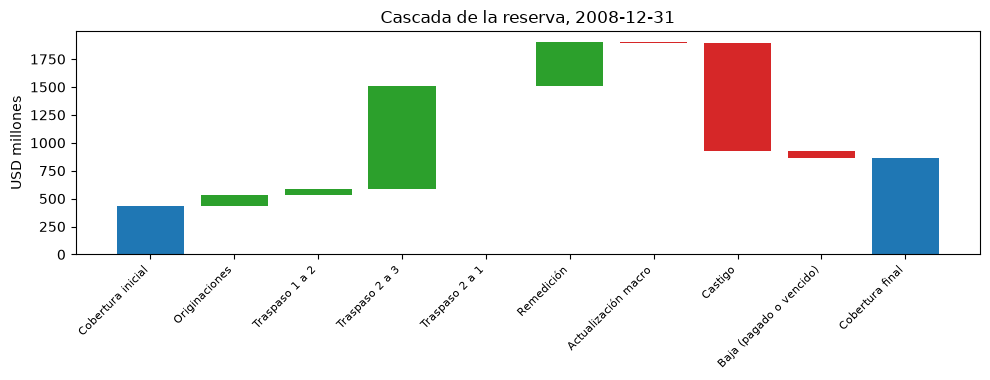

In [4]:
# Dibujar la cascada de la reserva: la apertura, cada movimiento y el cierre
lines = out["waterfall"]["lines"]
fig, ax = plt.subplots(figsize=(10, 3.9))
running = 0.0
for i, line in enumerate(lines):
    amount = line["amount"] / 1e6
    if line["kind"] in ("opening", "closing"):
        ax.bar(i, amount, color="tab:blue")
        running = amount
    else:
        ax.bar(i, abs(amount), bottom=running if amount >= 0 else running + amount,
               color="tab:green" if amount >= 0 else "tab:red")
        running += amount
labels = [line["label"]["es"] for line in lines]
for label, line in zip(labels, lines):
    print(f"{label:28s} {line['amount'] / 1e6:10.3f}")
ax.set_xticks(range(len(lines)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("USD millones")
ax.set_title("Cascada de la reserva, 2008-12-31")
fig.tight_layout()
plt.show()

La reserva abre en 433,600 millones de USD y cierra en 867,007 millones, la reserva ponderada del cuaderno 03. Las barras mayores son la transferencia de la Etapa 2 a la Etapa 3, 926,449 millones, y el castigo, 967,317 millones: los préstamos que caen en incumplimiento se castigan dentro del año, de modo que casi el mismo monto entra a la Etapa 3 y sale de ella, y no queda reserva de Etapa 3 a la fecha (hallazgo `F-NO-DELINQUENCY`). La nueva medición de 391,917 millones es el otro gran aumento, y la actualización macro, 9,308 millones, es una disminución pequeña.

### Paso 3: las identidades y su tolerancia

`identity_residuals` devuelve el residuo absoluto de cada identidad por nombre y `check_identities` los nombres de las que fallan. Necesitan las filas del paso 1, las líneas de la cascada del paso 2 y la PCE por etapa, que es el resumen por etapa versionado. La celda imprime cuántas identidades hay, el mayor residuo, la base de la tolerancia (una millonésima del importe en libros bruto $G$ de la cartera) y la luz de la prueba propia del motor `reconciliation_identities`.

In [5]:
# Juzgar las identidades, imprimir la base de la tolerancia y correr la prueba propia del motor
stage_ecl = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
G = rec.gross_total(gca)
test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="c06")
print("identidades:", len(residuals), "| mayor residuo, USD:", f"{max(residuals.values()):.1e}")
print("G, millones:", round(G / 1e6, 1))
print("límite absoluto 1e-6 x G, USD:", round(1e-6 * max(1.0, G), 1))
print("identidades que fallan:", rec.check_identities(allowance, gca, lines, stage_ecl))
print("prueba del motor, mayor residuo:", f"{test.metric:.0e}", "| luz:", LIGHT[test.light.value])
print("tolerancia, USD:", round(test.extras["tolerance"], 1))

identidades: 12 | mayor residuo, USD: 1.2e-07
G, millones: 47247.6
límite absoluto 1e-6 x G, USD: 47247.6
identidades que fallan: []
prueba del motor, mayor residuo: 1e-07 | luz: verde
tolerancia, USD: 47247.6


Doce identidades atan las tablas por etapa a la cascada y todas cierran: el mayor residuo es 1,2e-07 USD, frente a un límite absoluto de 47.247,6 USD, y la prueba propia del motor está en verde. La tolerancia merece una frase junto al resultado porque es relativa a la cartera: una millonésima de $G$, que es 47.247,6 millones de USD, es 47.247,6 USD, no una millonésima de dólar. Una compuerta con esa base protege contra un error del tamaño de un movimiento, que el paso siguiente mide.

### Paso 4: plantar un defecto y ver quién lo nombra

Una compuerta vale lo que detecta. La celda copia la fila de la reserva de la Etapa 1 y agrega a su nueva medición un defecto que el cierre no lleva, desde 1 USD hasta 100 millones de USD en 81 pasos, y pregunta a `check_identities` en cada tamaño si algo falla. Lo hace con la tolerancia por defecto de $10^{-6}$ y con una estricta de $10^{-9}$. La figura grafica detectado o no contra el tamaño, con el límite de cada tolerancia.

tolerancia 1e-06 | límite, USD: 47247.6
   menor defecto detectado, USD: 50118.7
tolerancia 1e-09 | límite, USD: 47.2
   menor defecto detectado, USD: 50.1


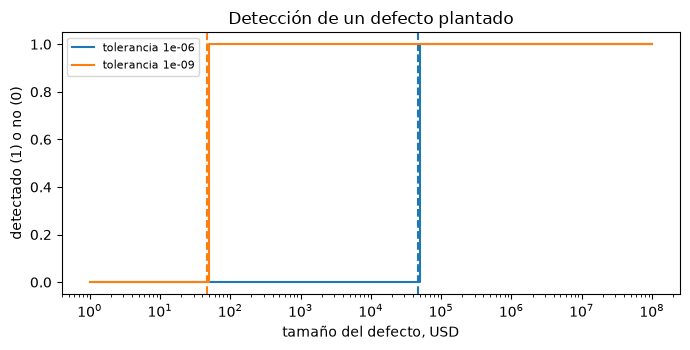

In [6]:
# Plantar un defecto de tamaño creciente en la fila de la Etapa 1 y preguntar desde qué tamaño lo nombra la compuerta
first = recon["allowance"][0]
sizes = np.logspace(0, 8, 81)
planted = [
    rec.allowance_rollforward(first["stage"], first["opening"],
                              {**allow_moves[0], "remeasurement": allow_moves[0]["remeasurement"] + size},
                              first["closing"])
    for size in sizes
]
caught = {}
fig, ax = plt.subplots(figsize=(7, 3.6))
for tolerance, color in ((1e-6, "tab:blue"), (1e-9, "tab:orange")):
    flags = [rec.check_identities([row] + allowance[1:], gca, lines, stage_ecl, tolerance=tolerance) for row in planted]
    caught[tolerance] = [bool(f) for f in flags]
    smallest = float(sizes[caught[tolerance].index(True)])
    print("tolerancia", tolerance, "| límite, USD:", round(tolerance * G, 1))
    print("   menor defecto detectado, USD:", round(smallest, 1))
    detected = np.array(caught[tolerance], dtype=float)
    ax.step(sizes, detected, where="post", color=color, label=f"tolerancia {tolerance}")
    ax.axvline(tolerance * G, color=color, linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("tamaño del defecto, USD")
ax.set_ylabel("detectado (1) o no (0)")
ax.set_title("Detección de un defecto plantado")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La compuerta nombra el defecto desde el tamaño de su límite y no antes: con la tolerancia por defecto no se detecta nada bajo 47.247,6 USD, y el primer tamaño de la grilla que se detecta es 50.118,7 USD, el primer punto de la grilla sobre el límite. Endurecer la tolerancia a $10^{-9}$ lleva el límite a 47,2 USD y el primer tamaño detectado a 50,1 USD. Las líneas discontinuas marcan los límites y los escalones suben justo después: la tolerancia es el umbral de detección, y un validador que informa una compuerta en verde debe informarla con este número.

### Paso 5: los ajustes como líneas separadas

C06 no tiene ajustes a esta fecha. La vista IFRS 9 de C07 tiene dos, versionados como líneas con un identificador, un segmento, una etapa y un monto. El `Overlay` del motor pide más: un método, un objetivo, un efecto en la clasificación y una fecha de revisión. La celda los construye desde las líneas versionadas, con el objetivo leído de la fila de diagnóstico versionada y una fecha de revisión que es un insumo de la lección. Luego pide a `overlay_lines` las líneas, a `total_allowance` el total sobre la PCE del modelo y a `overlay_diagnostics` la participación.

In [7]:
# Construir los ajustes del motor desde las líneas versionadas y calcular la reserva total y los diagnósticos
detail = base["outputs"]["ifrs9_detail"]
row = [t for t in base["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
by_target = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
REVIEW_DATE = "2026-08-31"  # lesson input: the artifact does not hold the review date
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert",
                target=by_target[o["amount"]], segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"],
                staging_effect="none", review_date=REVIEW_DATE, currency="CLP")
    for o in detail["overlays"]
]
for line in ovl.overlay_lines(overlays):
    print(line["id"], "| Etapa", line["stage"][-1], "| monto, CLP millones:", round(line["amount"] / 1e6, 3))
stage_model = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
model_total = sum(stage_model.values())
total = ovl.total_allowance(model_total, overlays)
print("PCE del modelo, CLP millones:", round(model_total / 1e6, 1))
print("reserva total, CLP millones:", round(total / 1e6, 1))
carried = rec.carried_by_stage(overlays)
print("llevado en la Etapa 1 y la Etapa 2, millones:")
print(round(carried["stage1"] / 1e6, 1), round(carried["stage2"] / 1e6, 1))
diag = ifrs9.overlay_diagnostics(overlays, stage_model, 0, model_id="c07")
print("participación de los ajustes en la reserva:", round(diag.metric, 6), "| luz:", LIGHT[diag.light.value])

overlay-OVL-CARDS | Etapa 1 | monto, CLP millones: 226.934
overlay-OVL-HOUSING | Etapa 2 | monto, CLP millones: 97.196
PCE del modelo, CLP millones: 97267.9
reserva total, CLP millones: 97592.0
llevado en la Etapa 1 y la Etapa 2, millones:
226.9 97.2
participación de los ajustes en la reserva: 0.003321 | luz: verde


Los dos ajustes de Banco Andino son 226,934 millones de CLP sobre tarjetas, llevados en la Etapa 1, y 97,196 millones sobre hipotecas de alto LTV, llevados en la Etapa 2. Son líneas propias, cada una con su fundamento, método y objetivo, y nunca entran a la PCE del modelo: la PCE del modelo es 97.267,9 millones de CLP y la reserva total es 97.592,0 millones, la suma. La participación de los ajustes en la reserva es 0,003321, 0,33%, que el diagnóstico lee como verde. Mantenidos aparte, los ajustes se pueden auditar uno a uno, algo que una sola cifra de PCE ajustada no permitiría.

### Paso 6: qué cambia el color de los diagnósticos

La luz de `overlay_diagnostics` lee la participación del ajuste en la reserva (ámbar sobre 10%, rojo sobre 25%) y la dirección: un ajuste positivo en un escenario que mejoró es inconsistente. La celda multiplica los ajustes del paso 5 por factores de 0 a 300, que son corridas hipotéticas y no datos de Contraste, y lee la participación y la luz en cada uno. También corre los mismos ajustes en un escenario que mejora para ver actuar la verificación de dirección. La figura grafica la participación contra el factor con los dos cortes.

ajustes multiplicados por 0 | participación: 0.0
    verde
ajustes multiplicados por 1 | participación: 0.0033
    verde
ajustes multiplicados por 25 | participación: 0.0769
    verde
ajustes multiplicados por 50 | participación: 0.1428
    ámbar
ajustes multiplicados por 100 | participación: 0.2499
    ámbar
ajustes multiplicados por 150 | participación: 0.3333
    rojo
ajustes multiplicados por 200 | participación: 0.3999
    rojo
ajustes multiplicados por 250 | participación: 0.4545
    rojo
ajustes multiplicados por 300 | participación: 0.4999
    rojo
escenario que mejora, ajustes positivos: luz: ámbar
dirección consistente: no


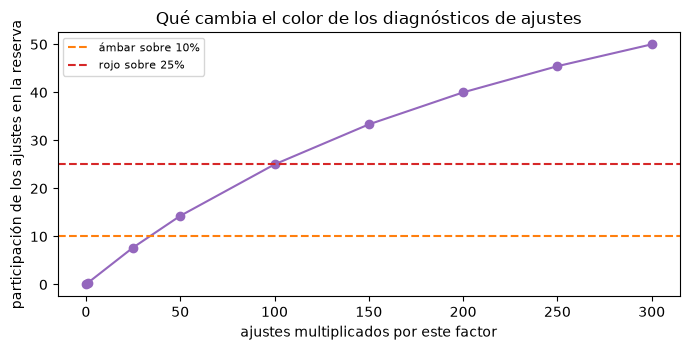

In [8]:
# Escalar los ajustes e invertir la dirección del escenario para ver la participación y la verificación de dirección
factors = [0, 1, 25, 50, 100, 150, 200, 250, 300]
shares = []
for factor in factors:
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    d = ifrs9.overlay_diagnostics(scaled, stage_model, 0)
    shares.append(d.metric)
    print("ajustes multiplicados por", factor, "| participación:", round(d.metric, 4))
    print("   ", LIGHT[d.light.value])
improving = ifrs9.overlay_diagnostics(overlays, stage_model, -1)
print("escenario que mejora, ajustes positivos: luz:", LIGHT[improving.light.value])
print("dirección consistente:", "sí" if improving.extras["direction_consistent"] else "no")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(factors, [100 * s for s in shares], marker="o", color="tab:purple")
ax.axhline(10, color="tab:orange", linestyle="--", label="ámbar sobre 10%")
ax.axhline(25, color="tab:red", linestyle="--", label="rojo sobre 25%")
ax.set_xlabel("ajustes multiplicados por este factor")
ax.set_ylabel("participación de los ajustes en la reserva")
ax.set_title("Qué cambia el color de los diagnósticos de ajustes")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con el tamaño versionado los ajustes son 0,33% de la reserva. Multiplicados por 25 son 7,7%, todavía en verde; multiplicados por 50 son 14%, ámbar; multiplicados por 100 son 24,99%, ámbar y apenas bajo el corte rojo de 25%; desde 150 son rojos. En un escenario que mejora, los mismos ajustes positivos hacen fallar la verificación de dirección y la luz pasa a ámbar, aunque la participación sea pequeña. Estas corridas muestran cómo se mueve el diagnóstico, con la participación en porcentaje en el eje vertical, y no dicen nada de los ajustes reales de Banco Andino.

### Paso 7: un ajuste que no sigue al escenario

Los ajustes de C07 están fijados en el caso en 10% y 8% de la PCE **base** de su segmento. La variante de recesión provisiona el mismo banco bajo un escenario más duro. La celda lee la PCE del modelo y el total de ajustes de ambas variantes, calcula la participación de los ajustes en la reserva total y verifica si los montos de los ajustes son los mismos en ambas. La figura dibuja la PCE del modelo y la participación de los ajustes por escenario.

base       | PCE del modelo, CLP millones:    97267.9
           | ajustes:  324.1
           | participación de los ajustes en el total: 0.00332
recesión   | PCE del modelo, CLP millones:   169463.6
           | ajustes:  324.1
           | participación de los ajustes en el total: 0.00191
montos de ajustes idénticos en ambas variantes: sí


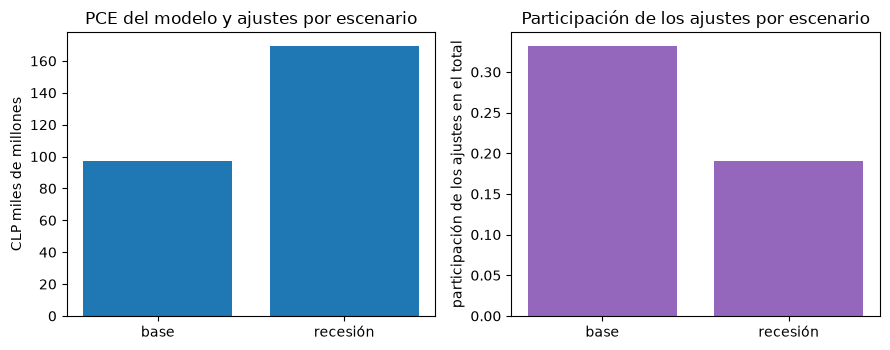

In [9]:
# Comparar la PCE del modelo y los ajustes de las variantes base y recesión de Banco Andino
variants = {"base": base, "recession": recession}
model_ecl, overlay_total, share = {}, {}, {}
for name, art in variants.items():
    d = art["outputs"]["ifrs9_detail"]
    model_ecl[name] = sum(r["ecl"] for r in d["stage_summary"])
    overlay_total[name] = d["overlays_total"]
    share[name] = overlay_total[name] / (model_ecl[name] + overlay_total[name])
    print(f"{SCENARIO[name]:10s} | PCE del modelo, CLP millones: {model_ecl[name] / 1e6:10.1f}")
    print(f"{'':10s} | ajustes: {overlay_total[name] / 1e6:6.1f}")
    print(f"{'':10s} | participación de los ajustes en el total: {share[name]:.5f}")
amounts = [[o["amount"] for o in a["outputs"]["ifrs9_detail"]["overlays"]] for a in variants.values()]
print("montos de ajustes idénticos en ambas variantes:", "sí" if amounts[0] == amounts[1] else "no")

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))
names = [SCENARIO[n] for n in variants]
left.bar(names, [model_ecl[n] / 1e9 for n in variants], color="tab:blue")
left.set_ylabel("CLP miles de millones")
left.set_title("PCE del modelo y ajustes por escenario")
right.bar(names, [100 * share[n] for n in variants], color="tab:purple")
right.set_ylabel("participación de los ajustes en el total")
right.set_title("Participación de los ajustes por escenario")
fig.tight_layout()
plt.show()

En la variante de recesión la PCE del modelo crece de 97.267,9 a 169.463,6 millones de CLP mientras que los ajustes se quedan en 324,1 millones, de modo que su participación en la reserva cae de 0,33% a 0,19%. Un ajuste dimensionado una vez sobre el caso base y que no se mueve cuando el escenario empeora protege menos justo cuando el banco lo necesita. Un validador lo lee como la firma de un ajuste sin un método detrás; el BCE (2024) pide que los ajustes descansen en un método como una simulación o un análisis de escenarios, que los dejaría moverse con el escenario.

## Resultados

**Respuesta:** Sí, la conciliación cierra: las 12 identidades se cumplen con un mayor residuo de 1,2e-07 USD frente a un límite de 47.247,6 USD, y la reserva de la cartera de 2008 crece de 433,600 a 867,007 millones de USD principalmente por nueva medición (391,917 millones) y originaciones (99,569 millones), con 926,449 millones transferidos a la Etapa 3 y 967,317 millones castigados; los dos ajustes de Banco Andino suman 324,1 millones de CLP, 0,33% de la reserva (0,003321), y se quedan en 324,1 cuando la PCE del modelo crece de 97.267,9 a 169.463,6 millones.

- **La conciliación cierra.** Las seis filas por etapa (tres de la reserva, tres del importe en libros bruto) se reconstruyen con el motor y tienen residuos de a lo más 1e-07 USD. En la Etapa 1 la reserva va de 433,354 a 798,078 millones de USD y en la Etapa 2 de 0,246 a 68,929; el importe en libros bruto de la Etapa 1 va de 47.338,013 a 46.716,271 millones. Un movimiento fuera de la lista de IFRS 7 35I se rechaza.
- **Doce identidades se cumplen.** `check_identities` devuelve una lista vacía y la prueba propia del motor está en verde. La cascada abre en 433,600 millones, la suma de las tres aperturas por etapa, y cierra en 867,007, la reserva del cuaderno 03.
- **La tolerancia es relativa, y eso es una propiedad que hay que declarar.** $G$ es 47.247,6 millones de USD, así que el límite por defecto es 47.247,6 USD. Un defecto se detecta por primera vez en la grilla en 50.118,7 USD; con la tolerancia endurecida a $10^{-9}$, en 50,1 USD. La compuerta protege la cartera contra un error del tamaño de un movimiento, no contra un redondeo de unos miles de USD.
- **La Etapa 3 cierra en cero por construcción de los datos.** La transferencia de la Etapa 2 a la Etapa 3 es 926,449 millones y el castigo es 967,317 millones: los préstamos caen en incumplimiento y se castigan dentro del año, y no queda reserva de Etapa 3 a la fecha (hallazgo `F-NO-DELINQUENCY`).
- **Los ajustes son líneas, y el total concilia.** Los dos ajustes de Banco Andino son 226,934 millones de CLP (tarjetas, Etapa 1) y 97,196 (hipotecas de alto LTV, Etapa 2). La PCE del modelo es 97.267,9 millones, la reserva total 97.592,0, y la participación de los ajustes es 0,003321, en verde.
- **Los diagnósticos se mueven como dicen las reglas.** Los mismos ajustes multiplicados por 100 son 24,99% de la reserva, ámbar y apenas bajo el corte rojo de 25%; multiplicados por 150 o más son rojos. En un escenario que mejora, un ajuste positivo hace fallar la verificación de dirección y la luz pasa a ámbar. Son corridas hipotéticas.
- **Un ajuste que no sigue al escenario.** En la variante de recesión la PCE del modelo crece de 97.267,9 a 169.463,6 millones de CLP y los ajustes se quedan en 324,1, de modo que su participación cae de 0,33% a 0,19%. Un validador lo lee como un ajuste dimensionado una vez sobre el caso base.

Lo que este cuaderno no muestra: el cierre de las identidades es una afirmación sobre la consistencia aritmética de las tablas, no sobre si la reserva es correcta, y el motor no declara cumplimiento. La fecha de revisión de los ajustes es un insumo de la lección, y C07 es un banco sintético.

## Resumen

- La conciliación IFRS 7 de la reserva y del importe en libros bruto se reconstruye fila por fila con el motor, y doce identidades atan las tablas por etapa a la cascada.
- La compuerta cierra con una tolerancia de una millonésima del importe en libros bruto de la cartera, así que detecta un error del tamaño de un movimiento y deja pasar unos miles de USD; un validador declara la base junto al resultado.
- Los ajustes son líneas separadas y atribuidas que entran solo a la reserva total, nunca a la PCE del modelo ni a la PCE por etapa; el motor lleva un ajuste sin etapa en la Etapa 1 por convención.
- Los diagnósticos de ajustes leen la participación en la reserva, su desglose y la dirección frente al escenario; un ajuste fijado en el caso no sigue a un escenario más duro.
- Una identidad que cierra dice que las tablas concuerdan entre sí, no que la reserva sea adecuada.

**Qué probar después.** Planta un defecto en otro movimiento, o en la tabla del importe en libros bruto, y lee qué identidades lo nombran; cambia `REVIEW_DATE` y comprueba que los totales no se mueven. Luego sigue con el cuaderno 05, que valida toda la batería en seis fechas de reporte.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf